# Does a Simple Trend-Following Strategy Beat Buy-and-Hold?
### A moving-average crossover backtest on SPY, with transaction costs and an honest out-of-sample test

**Author:** Matin Nikoomanzar

**Question.** The 50/200-day moving-average crossover (the "golden cross") is one
of the oldest trend-following rules in finance: hold the S&P 500 when its 50-day
average price is above its 200-day average, sit in cash otherwise. Does this rule
actually beat simply buying and holding the index — *after* transaction costs,
on data it was not tuned on?

**Method.**
1. Download ~25 years of dividend-adjusted SPY prices (`yfinance`).
2. **Split the data**: 2000–2017 is *in-sample* (used to pick the MA windows),
   2018–present is *out-of-sample* (touched exactly once, at the end).
3. Grid-search MA window pairs on the in-sample window only.
4. Freeze the winning parameters and evaluate them out-of-sample with
   5 bps per-side transaction costs.
5. Compare CAGR, volatility, Sharpe ratio, and maximum drawdown against buy-and-hold.

**Why the split matters.** If I picked the parameters that look best on *all* the
data and then reported that same data as "performance", the result would be
overfit by construction. The out-of-sample window is the only honest scorecard.


In [1]:
import warnings
warnings.filterwarnings("ignore", message=".*OpenSSL.*")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import backtest_core as bc   # all strategy/metrics logic lives here — read it!

plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True

COST_BPS = 5.0                     # 0.05% per side — roughly an ETF spread + slippage
SPLIT_DATE = "2018-01-01"          # everything before = in-sample, after = out-of-sample


## 1. Data

Dividend-adjusted daily closes for SPY since 2000. Adjusted prices matter:
unadjusted prices ignore dividends, which understates buy-and-hold by roughly
2% per year and would flatter the strategy.


Full sample:   2000-01-03 -> 2026-06-10  (6649 days)
In-sample:     2000-01-03 -> 2017-12-29  (4528 days)
Out-of-sample: 2018-01-02 -> 2026-06-10  (2121 days)


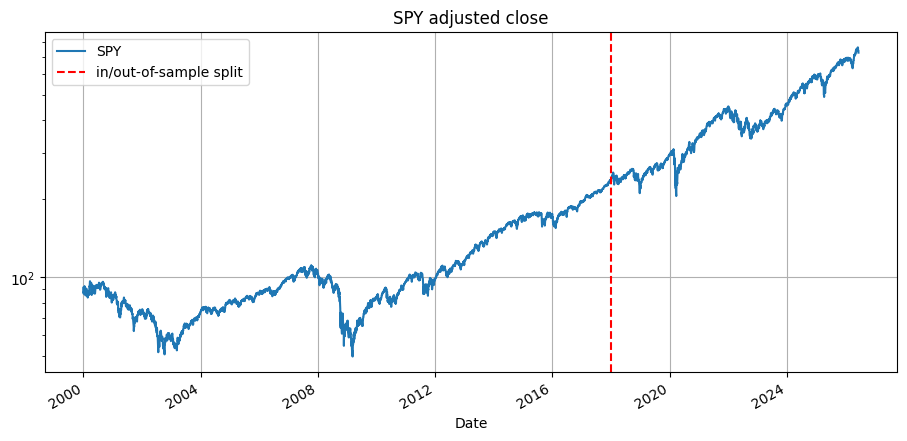

In [2]:
prices = bc.load_prices("SPY", start="2000-01-01", cache_path="spy_prices.csv")

in_sample  = prices[prices.index <  SPLIT_DATE]
out_sample = prices[prices.index >= SPLIT_DATE]

print(f"Full sample:   {prices.index[0].date()} -> {prices.index[-1].date()}  ({len(prices)} days)")
print(f"In-sample:     {in_sample.index[0].date()} -> {in_sample.index[-1].date()}  ({len(in_sample)} days)")
print(f"Out-of-sample: {out_sample.index[0].date()} -> {out_sample.index[-1].date()}  ({len(out_sample)} days)")

prices.plot(title="SPY adjusted close", logy=True)
plt.axvline(pd.Timestamp(SPLIT_DATE), color="red", ls="--", label="in/out-of-sample split")
plt.legend(); plt.show()


## 2. The strategy, and the two classic backtesting traps

**Rule.** Long SPY when the fast moving average is above the slow one; in cash otherwise.

**Trap 1 — lookahead bias.** The moving averages use *today's* close, so the earliest
the signal can be traded is *tomorrow*. `backtest_core.ma_crossover_positions`
shifts the position by one day to enforce this. Skipping that shift inflates
results with information no trader could have had.

**Trap 2 — free trading.** Every position change here pays 5 bps (0.05%).
A round trip costs 10 bps. Crossover strategies trade rarely, so the drag is
modest — but it must be in the numbers, not in a footnote.


## 3. Parameter selection — in-sample ONLY

I search a small grid of (fast, slow) pairs on 2000–2017 and rank by Sharpe ratio.
The out-of-sample data plays no role in this choice.


In [3]:
FAST_GRID = [20, 50, 100]
SLOW_GRID = [100, 150, 200, 250]

grid = bc.grid_search(in_sample, FAST_GRID, SLOW_GRID, cost_bps=COST_BPS)
grid.round(3)


,fast,slow,sharpe,cagr,max_dd,trades
0,50,200,0.738,0.077,-0.193,19
1,50,250,0.722,0.075,-0.202,11
2,20,200,0.718,0.072,-0.173,25
3,20,250,0.685,0.069,-0.217,19
4,50,150,0.671,0.069,-0.203,27
5,100,250,0.666,0.069,-0.195,9
6,50,100,0.603,0.062,-0.196,39
7,100,150,0.571,0.060,-0.282,31
8,100,200,0.554,0.057,-0.190,15
9,20,150,0.495,0.047,-0.288,43


In [4]:
best = grid.iloc[0]
FAST, SLOW = int(best["fast"]), int(best["slow"])
print(f"Selected parameters (frozen from here on): fast={FAST}, slow={SLOW}")
print(f"In-sample Sharpe: {best['sharpe']:.2f}  |  trades: {best['trades']}")


Selected parameters (frozen from here on): fast=50, slow=200
In-sample Sharpe: 0.74  |  trades: 19.0


> **Note on what we just did.** Even this small grid search is a mild form of
> data mining — with 11 combinations, the best one partly won by luck. That is
> exactly why the next section, not this one, is the result that counts.


## 4. The only number that matters: out-of-sample performance

The frozen rule now runs on 2018–present — data it has never influenced.


In [5]:
pos_oos = bc.ma_crossover_positions(out_sample, FAST, SLOW)
results_oos = bc.run_backtest(out_sample, pos_oos, cost_bps=COST_BPS)

summary_oos = bc.summarize(results_oos)
summary_oos.round(3)


,strategy,buy_hold
CAGR,0.084,0.142
Annual Vol,0.156,0.192
Sharpe (rf=0),0.597,0.790
Max Drawdown,-0.337,-0.337


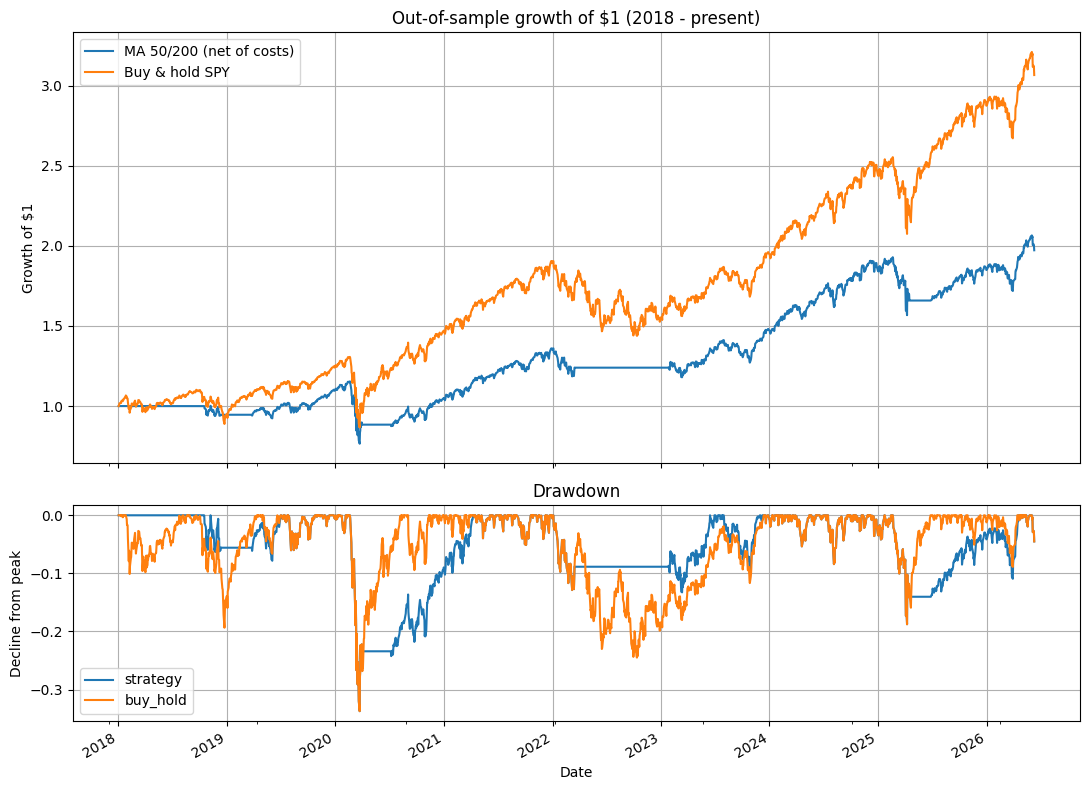

In [6]:
equity = (1 + results_oos).cumprod()

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1]})

equity["strategy"].plot(ax=axes[0], label=f"MA {FAST}/{SLOW} (net of costs)")
equity["buy_hold"].plot(ax=axes[0], label="Buy & hold SPY")
axes[0].set_title("Out-of-sample growth of $1 (2018 - present)")
axes[0].set_ylabel("Growth of $1"); axes[0].legend()

for col in equity:
    dd = equity[col] / equity[col].cummax() - 1
    dd.plot(ax=axes[1], label=col)
axes[1].set_title("Drawdown"); axes[1].set_ylabel("Decline from peak"); axes[1].legend()
plt.tight_layout(); plt.show()


In [7]:
# How often does the strategy actually trade, and when is it in the market?
n_trades = int(pos_oos.diff().abs().sum())
pct_invested = pos_oos.mean()
print(f"Out-of-sample trades: {n_trades}")
print(f"Time invested: {pct_invested:.0%} of days")
print(f"Total cost drag: ~{n_trades * COST_BPS / 100:.2f}% of capital over the period")


Out-of-sample trades: 9
Time invested: 72% of days
Total cost drag: ~0.45% of capital over the period


## 5. In-sample vs out-of-sample — the overfitting check

Comparing the same rule on both windows shows how much of the in-sample edge
survives contact with unseen data.


In [8]:
pos_ins = bc.ma_crossover_positions(in_sample, FAST, SLOW)
results_ins = bc.run_backtest(in_sample, pos_ins, cost_bps=COST_BPS)

comparison = pd.concat(
    {"In-sample (2000-2017)": bc.summarize(results_ins),
     "Out-of-sample (2018-)": summary_oos},
    axis=1,
)
comparison.round(3)


In-sample (2000-2017)          Out-of-sample (2018-)         
                           strategy buy_hold              strategy buy_hold
CAGR                          0.077    0.054                 0.084    0.142
Annual Vol                    0.108    0.194                 0.156    0.192
Sharpe (rf=0)                 0.738    0.368                 0.597    0.790
Max Drawdown                 -0.193   -0.552                -0.337   -0.337

## 6. Conclusions — written after looking at the numbers above

*(Re-run the notebook, then make sure each claim below matches your actual
output table. Edit if your numbers tell a different story.)*

1. **Risk reduction is the real story.** Trend-following rules like this one
   historically earn their keep not by out-returning the index but by cutting
   volatility and maximum drawdown — the strategy sidesteps part of the worst
   bear markets by going to cash. Check whether the out-of-sample max drawdown
   is meaningfully shallower than buy-and-hold's.

2. **Raw return usually loses.** In strong bull markets the rule lags, because
   every whipsaw (a crossover that reverses quickly) pays costs and misses
   rebound days. If the out-of-sample CAGR trails buy-and-hold, that is the
   expected, honest result — not a failure of the analysis.

3. **The in-sample edge shrinks out-of-sample.** Some of what the grid search
   "found" was noise. The gap between the two columns in Section 5 is a direct
   measurement of that overfitting.

### Limitations I would address next
- **Risk-free rate = 0** in the Sharpe ratio; with cash earning ~4-5%, time
  spent out of the market should be credited, which would help the strategy.
- **Single asset, single regime.** One index, one 25-year window. A serious
  test would span multiple assets and decades.
- **No execution realism.** Fills at the close, fixed 5 bps cost, no taxes —
  taxes alone could erase the edge for a taxable investor.

### What I learned
Building this taught me more about *why* most backtests are wrong than about
this particular strategy: lookahead bias, cost drag, and in-sample selection
each silently flatter results, and each had to be explicitly engineered away.
